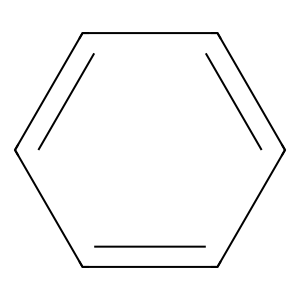

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
m=Chem.MolFromSmiles("c1ccccc1")
Draw.MolToImage(m)

In [ ]:
Chem.MolToSmiles(Chem.MolFromSmiles('C1=CC=CN=C1'))

'c1ccncc1'

In [ ]:
import pandas as pd
import numpy as np
from chembl_webresource_client.new_client import new_client

activity = new_client.activity

def fetch_target_data(target_chembl_id, target_label):
    print(f"Fetching data for {target_label} ({target_chembl_id})...")
    res = activity.filter(
        target_chembl_id=target_chembl_id,
        standard_type="IC50",
        standard_units="nM"
    ).only(['molecule_chembl_id', 'canonical_smiles', 'standard_value'])
    
    rows = []
    for r in res:
        val = r.get('standard_value')
        smi = r.get('canonical_smiles')
        cid = r.get('molecule_chembl_id')
        if val is not None and smi:
            try:
                v = float(val)
                if v > 0:
                    rows.append({'chembl_id': cid, 'smiles': smi, 'ic50_nM': v})
            except ValueError:
                continue
                
    df = pd.DataFrame(rows)
    # Deduplicate by median value
    df = df.groupby(['chembl_id', 'smiles'])['ic50_nM'].median().reset_index()
    # Calculate pIC50
    df['pIC50'] = 9.0 - np.log10(df['ic50_nM'])
    df['target'] = target_label
    print(f"-> Extracted {len(df)} unique compounds for {target_label}.")
    return df

# Target 1: Caspase-3 (Executioner of Apoptosis)
df_apop = fetch_target_data("CHEMBL2334", "Caspase-3")

# Target 2: EGFR (Hallmark Cancer Signaling Kinase)
df_sign = fetch_target_data("CHEMBL203", "EGFR")

# Save locally to avoid re-querying
df_apop.to_csv("caspase3_apoptosis.csv", index=False)
df_sign.to_csv("egfr_signaling.csv", index=False)
print("Target datasets saved locally.")

Fetching data for Caspase-3 (CHEMBL2334)...
-> Extracted 2177 unique compounds for Caspase-3.
Fetching data for EGFR (CHEMBL203)...
-> Extracted 13577 unique compounds for EGFR.
Target datasets saved locally.


In [ ]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict
import numpy as np

def scaffold_split(df, smiles_col='smiles', test_size=0.2, random_state=42):
    """
    Groups molecules by their Bemis-Murcko core scaffold and partitions
    entire scaffold clusters into train and test sets to prevent data leakage.
    """
    scaffolds = defaultdict(list)
    
    for idx, smi in enumerate(df[smiles_col]):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            # Extract the core topological ring-and-linker framework
            scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
            scaffolds[scaffold].append(idx)
        else:
            scaffolds['invalid'].append(idx)
            
    # Sort scaffold sets by size (largest to smallest) for balanced distribution
    scaffold_clusters = sorted(scaffolds.values(), key=lambda x: len(x), reverse=True)
    
    train_indices = []
    test_indices = []
    total_samples = len(df)
    test_cutoff = int(total_samples * test_size)
    
    # Assign clusters deterministically / pseudo-randomly
    np.random.seed(random_state)
    np.random.shuffle(scaffold_clusters)
    
    for cluster in scaffold_clusters:
        if len(test_indices) + len(cluster) <= test_cutoff:
            test_indices.extend(cluster)
        else:
            train_indices.extend(cluster)
            
    return np.array(train_indices), np.array(test_indices)

In [ ]:
import numpy as np
import pandas as pd
from collections import defaultdict
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

# 1. Initialize modern Morgan generator (1024 bits, radius 2)
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_fp(smi):
    mol = Chem.MolFromSmiles(smi)
    return np.array(mfpgen.GetFingerprint(mol)) if mol else None

def generate_fps_and_filter(df):
    fps, valid_idx = [], []
    for idx, smi in enumerate(df['smiles']):
        fp = smiles_to_fp(smi)
        if fp is not None:
            fps.append(fp)
            valid_idx.append(idx)
    return np.array(fps), df.iloc[valid_idx].reset_index(drop=True)

# 2. Load existing datasets from disk
df_apop = pd.read_csv("caspase3_apoptosis.csv")
df_sign = pd.read_csv("egfr_signaling.csv")

if len(df_sign) > 5000:
    df_sign = df_sign.sample(n=5000, random_state=42).reset_index(drop=True)

X_apop, df_apop_clean = generate_fps_and_filter(df_apop)
y_apop = df_apop_clean['pIC50'].values

X_sign, df_sign_clean = generate_fps_and_filter(df_sign)
y_sign = df_sign_clean['pIC50'].values

# 3. Scaffold Split Function
def scaffold_split(df, smiles_col='smiles', test_size=0.2, random_state=42):
    scaffolds = defaultdict(list)
    for idx, smi in enumerate(df[smiles_col]):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
            scaffolds[scaffold].append(idx)
        else:
            scaffolds['invalid'].append(idx)
            
    scaffold_clusters = sorted(scaffolds.values(), key=lambda x: len(x), reverse=True)
    np.random.seed(random_state)
    np.random.shuffle(scaffold_clusters)
    
    train_idx, test_idx = [], []
    test_cutoff = int(len(df) * test_size)
    for cluster in scaffold_clusters:
        if len(test_idx) + len(cluster) <= test_cutoff:
            test_idx.extend(cluster)
        else:
            train_idx.extend(cluster)
    return np.array(train_idx), np.array(test_idx)

# 4. Partition datasets
train_idx_a, test_idx_a = scaffold_split(df_apop_clean, test_size=0.2)
X_train_a, X_test_a = X_apop[train_idx_a], X_apop[test_idx_a]
y_train_a, y_test_a = y_apop[train_idx_a], y_apop[test_idx_a]

train_idx_s, test_idx_s = scaffold_split(df_sign_clean, test_size=0.2)
X_train_s, X_test_s = X_sign[train_idx_s], X_sign[test_idx_s]
y_train_s, y_test_s = y_sign[train_idx_s], y_sign[test_idx_s]

print(f"Caspase-3 -> Train: {len(X_train_a)}, Test: {len(X_test_a)}")
print(f"EGFR      -> Train: {len(X_train_s)}, Test: {len(X_test_s)}")

Caspase-3 -> Train: 1742, Test: 435
EGFR      -> Train: 4000, Test: 1000


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# 1. XGBoost for Apoptosis (Caspase-3)
xgb_apop = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_apop.fit(X_train_a, y_train_a)
preds_xgb_a = xgb_apop.predict(X_test_a)

print("=== Optimized XGBoost: Apoptosis (Caspase-3) ===")
print(f"R² Score: {r2_score(y_test_a, preds_xgb_a):.3f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test_a, preds_xgb_a)):.3f}")

# 2. XGBoost for Signaling (EGFR)
xgb_sign = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_sign.fit(X_train_s, y_train_s)
preds_xgb_s = xgb_sign.predict(X_test_s)

print("\n=== Optimized XGBoost: Signaling (EGFR) ===")
print(f"R² Score: {r2_score(y_test_s, preds_xgb_s):.3f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test_s, preds_xgb_s)):.3f}")

=== Optimized XGBoost: Apoptosis (Caspase-3) ===
R² Score: 0.796
RMSE:     0.622

=== Optimized XGBoost: Signaling (EGFR) ===
R² Score: 0.542
RMSE:     0.942


In [ ]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# Re-use your Morgan generator
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_fp(smi):
    mol = Chem.MolFromSmiles(smi)
    return np.array(mfpgen.GetFingerprint(mol)) if mol else None

# 1. Manually add the 5 derivatives from your reference image
paper_molecules = [
    {
        "chembl_id": "Derivative_a (Curcumin)",
        "smiles": "O=C(/C=C/c1ccc(O)c(OC)c1)CC(=O)/C=C/c2ccc(O)c(OC)c2",
        "description": "Native Curcumin (beta-diketone)"
    },
    {
        "chembl_id": "Derivative_b",
        "smiles": "COc1cc(/C=C/C(=O)C(O)C(=O)/C=C/c2ccc(O)c(OC)c2)ccc1O",
        "description": "Hydroxylated beta-diketone"
    },
    {
        "chembl_id": "Derivative_c",
        "smiles": "COc1cc(/C=C/c2cc(/C=C/c3ccc(O)c(OC)c3)n(C(=O)COc3ccccc3)n2)ccc1O",
        "description": "Pyrazole analog with phenoxyacetyl"
    },
    {
        "chembl_id": "Derivative_d",
        "smiles": "COc1cc(/C=C/c2cc(/C=C/c3ccc(O)c(OC)c3)n(C(=O)COc3ccc(Cl)cc3Cl)n2)ccc1O",
        "description": "Pyrazole analog with 2,4-dichlorophenoxyacetyl"
    },
    {
        "chembl_id": "Derivative_e",
        "smiles": "COc1ccccc1NC(=O)n1nc(/C=C/c2ccc(O)c(OC)c2)cc1/C=C/c3ccc(O)c(OC)c3",
        "description": "Pyrazole analog with 2-methoxyphenylurea"
    }
]

df_paper = pd.DataFrame(paper_molecules)

# 2. Compute fingerprints and predict
fps = np.array([smiles_to_fp(s) for s in df_paper['smiles']])

df_paper['pred_pIC50_apop'] = xgb_apop.predict(fps)
df_paper['pred_pIC50_sign'] = xgb_sign.predict(fps)
df_paper['delta_score'] = df_paper['pred_pIC50_apop'] - df_paper['pred_pIC50_sign']

# 3. Categorize mechanism dominance
def classify_dominance(delta, margin=0.3):
    if delta > margin:
        return "Apoptosis Dominant"
    elif delta < -margin:
        return "Signaling Dominant"
    else:
        return "Balanced / Dual-Action"

df_paper['Dominant_Mechanism'] = df_paper['delta_score'].apply(classify_dominance)

# Display the comparison table
display_cols = ['chembl_id', 'description', 'pred_pIC50_apop', 'pred_pIC50_sign', 'delta_score', 'Dominant_Mechanism']
df_paper[display_cols]

,chembl_id,description,pred_pIC50_apop,pred_pIC50_sign,delta_score,Dominant_Mechanism
0,Derivative_a (Curcumin),Native Curcumin (beta-diketone),4.596677,4.946115,-0.349438,Signaling Dominant
1,Derivative_b,Hydroxylated beta-diketone,4.700657,4.947322,-0.246665,Balanced / Dual-Action
2,Derivative_c,Pyrazole analog with phenoxyacetyl,4.208986,5.695762,-1.486776,Signaling Dominant
3,Derivative_d,"Pyrazole analog with 2,4-dichlorophenoxyacetyl",4.521698,5.141877,-0.620179,Signaling Dominant
4,Derivative_e,Pyrazole analog with 2-methoxyphenylurea,4.551391,5.211905,-0.660514,Signaling Dominant


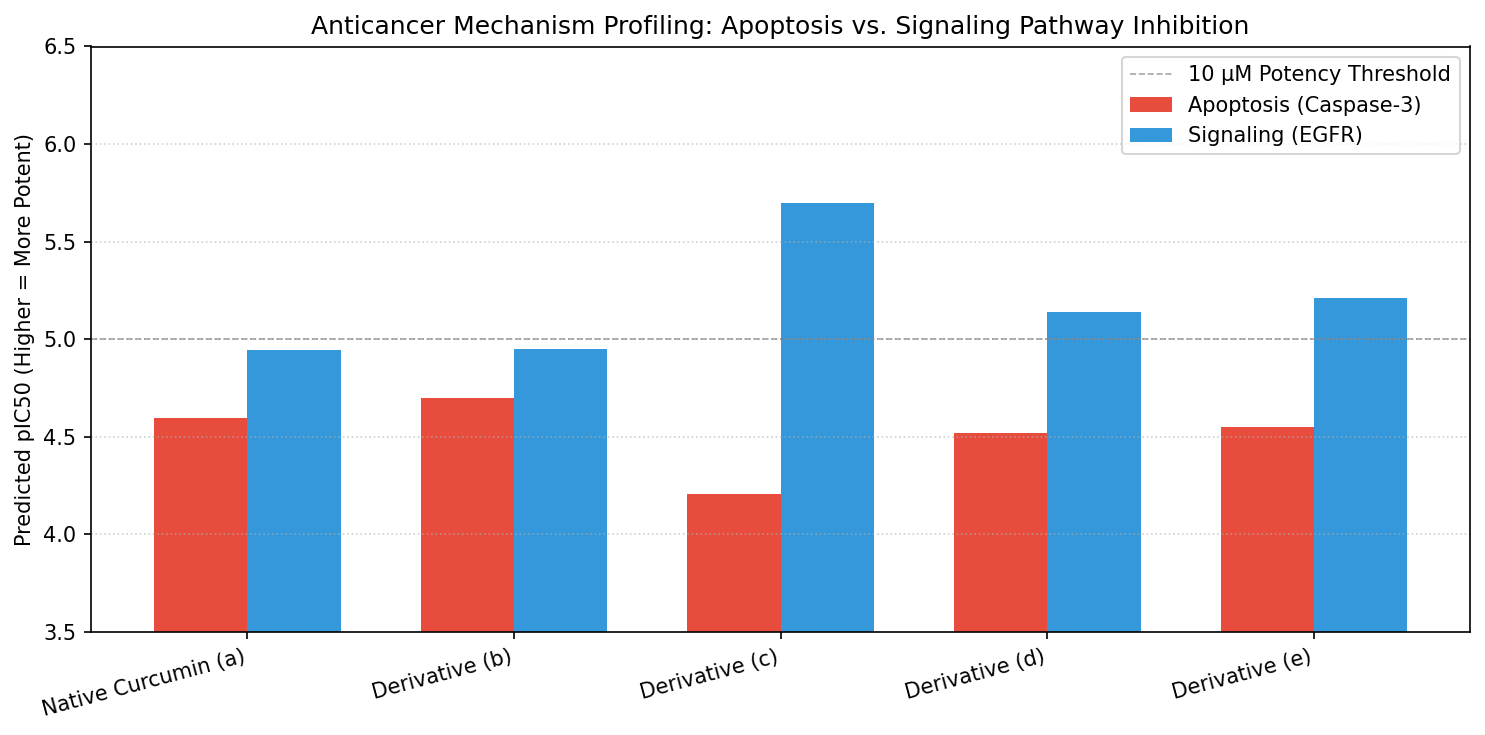

In [ ]:
import matplotlib.pyplot as plt

# Bar chart comparing Apoptosis vs Signaling across the 5 analogs
labels = ['Native Curcumin (a)', 'Derivative (b)', 'Derivative (c)', 'Derivative (d)', 'Derivative (e)']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
rects1 = ax.bar(x - width/2, df_paper['pred_pIC50_apop'], width, label='Apoptosis (Caspase-3)', color='#e74c3c')
rects2 = ax.bar(x + width/2, df_paper['pred_pIC50_sign'], width, label='Signaling (EGFR)', color='#3498db')

ax.set_ylabel('Predicted pIC50 (Higher = More Potent)')
ax.set_title('Anticancer Mechanism Profiling: Apoptosis vs. Signaling Pathway Inhibition')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15, ha='right')
ax.set_ylim(3.5, 6.5)
ax.axhline(5.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7, label='10 µM Potency Threshold')
ax.legend()
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("mechanism_comparison.png")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the raw bioactivity dataset and get unique compounds
df_raw = pd.read_csv("curcumin_bioactivity_raw.csv")
df_unique = df_raw[['chembl_id', 'smiles']].drop_duplicates().dropna().reset_index(drop=True)

print(f"Total unique curcumin analogs to screen: {len(df_unique)}")

# 2. Generate Morgan fingerprints
fps_list = []
valid_idx = []

for idx, smi in enumerate(df_unique['smiles']):
    fp = smiles_to_fp(smi)
    if fp is not None:
        fps_list.append(fp)
        valid_idx.append(idx)

X_screen = np.array(fps_list)
df_screened = df_unique.iloc[valid_idx].copy().reset_index(drop=True)

# 3. Predict Apoptosis and Signaling potencies using XGBoost
df_screened['pred_pIC50_apop'] = xgb_apop.predict(X_screen)
df_screened['pred_pIC50_sign'] = xgb_sign.predict(X_screen)

# 4. Compute Delta Dominance Score
df_screened['delta_score'] = df_screened['pred_pIC50_apop'] - df_screened['pred_pIC50_sign']

# 5. Classify Dominance (|Δ| > 0.3 log units threshold ~ 2-fold selectivity)
def classify_dominance(delta, margin=0.3):
    if delta > margin:
        return "Apoptosis Dominant"
    elif delta < -margin:
        return "Signaling Dominant"
    else:
        return "Balanced / Dual-Action"

df_screened['dominant_mechanism'] = df_screened['delta_score'].apply(classify_dominance)

# Save the full screened dataset
df_screened.to_csv("curcumin_all_screened_mechanisms.csv", index=False)
print("Screening complete. Saved to 'curcumin_all_screened_mechanisms.csv'.")

# 6. Statistical Summary
print("\n" + "="*45)
print("       MECHANISM DOMINANCE BREAKDOWN")
print("="*45)
summary_counts = df_screened['dominant_mechanism'].value_counts()
summary_pcts = df_screened['dominant_mechanism'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({'Count': summary_counts, 'Percentage (%)': summary_pcts.round(2)})
print(summary_df)

print("\n--- Summary Statistics for Delta Score ---")
print(df_screened['delta_score'].describe().round(3))

Total unique curcumin analogs to screen: 57
Screening complete. Saved to 'curcumin_all_screened_mechanisms.csv'.

       MECHANISM DOMINANCE BREAKDOWN
                        Count  Percentage (%)
dominant_mechanism                           
Signaling Dominant         33           57.89
Balanced / Dual-Action     23           40.35
Apoptosis Dominant          1            1.75

--- Summary Statistics for Delta Score ---
count    57.000
mean     -0.448
std       0.373
min      -1.255
25%      -0.663
50%      -0.395
75%      -0.179
max       0.330
Name: delta_score, dtype: float64


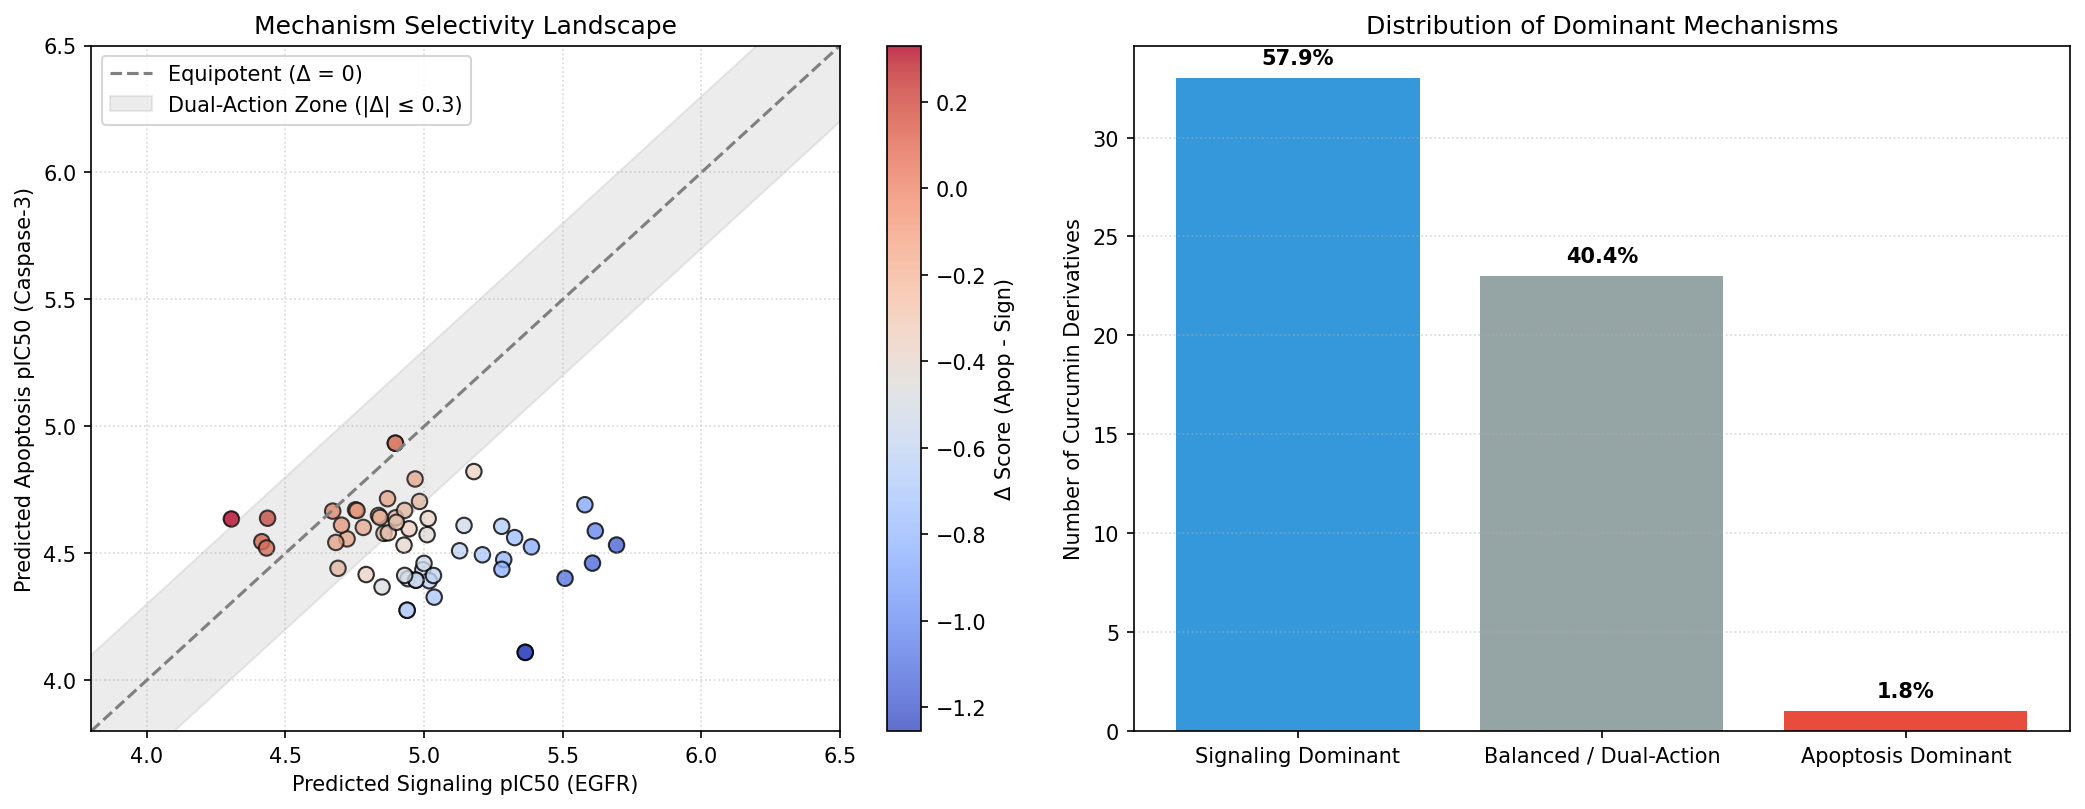

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# Panel 1: Selectivity Scatter Plot
scatter = axes[0].scatter(
    df_screened['pred_pIC50_sign'], 
    df_screened['pred_pIC50_apop'], 
    c=df_screened['delta_score'], 
    cmap='coolwarm', 
    alpha=0.8, 
    edgecolor='k', 
    s=55
)

# Diagonal parity line (equal potency)
lims = [
    min(axes[0].get_xlim()[0], axes[0].get_ylim()[0], 3.8),
    max(axes[0].get_xlim()[1], axes[0].get_ylim()[1], 6.5)
]
axes[0].plot(lims, lims, '--', color='gray', label='Equipotent (Δ = 0)')
axes[0].fill_between(lims, [x - 0.3 for x in lims], [x + 0.3 for x in lims], color='gray', alpha=0.15, label='Dual-Action Zone (|Δ| ≤ 0.3)')

axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel('Predicted Signaling pIC50 (EGFR)')
axes[0].set_ylabel('Predicted Apoptosis pIC50 (Caspase-3)')
axes[0].set_title('Mechanism Selectivity Landscape')
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(linestyle=':', alpha=0.5)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('Δ Score (Apop - Sign)')

# Panel 2: Dominance Distribution Bar Chart
palette = {'Signaling Dominant': '#3498db', 'Balanced / Dual-Action': '#95a5a6', 'Apoptosis Dominant': '#e74c3c'}
bars = axes[1].bar(summary_df.index, summary_df['Count'], color=[palette.get(c, '#333333') for c in summary_df.index])
axes[1].set_ylabel('Number of Curcumin Derivatives')
axes[1].set_title('Distribution of Dominant Mechanisms')
axes[1].grid(axis='y', linestyle=':', alpha=0.5)

# Add percentages on bars
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df_screened)) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{pct:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("curcumin_mechanism_landscape.png")
plt.show()

In [ ]:
# 1. Inspect the single Apoptosis-dominant compound
outlier_apop = df_screened[df_screened['dominant_mechanism'] == 'Apoptosis Dominant']
print("=== LONE APOPTOSIS DOMINANT COMPOUND ===")
print(outlier_apop[['chembl_id', 'pred_pIC50_apop', 'pred_pIC50_sign', 'delta_score', 'smiles']])

# 2. Inspect the Top 3 strongest Signaling inhibitors
top_sign = df_screened.sort_values(by='delta_score', ascending=True).head(3)
print("\n=== TOP 3 SIGNALING-DOMINANT COMPOUNDS ===")
print(top_sign[['chembl_id', 'pred_pIC50_apop', 'pred_pIC50_sign', 'delta_score', 'smiles']])

=== LONE APOPTOSIS DOMINANT COMPOUND ===
     chembl_id  pred_pIC50_apop  pred_pIC50_sign  delta_score  \
3  CHEMBL32749         4.635326         4.305327     0.329999   

                     smiles  
3  COc1cc(/C=C/C(=O)O)ccc1O  

=== TOP 3 SIGNALING-DOMINANT COMPOUNDS ===
        chembl_id  pred_pIC50_apop  pred_pIC50_sign  delta_score  \
9    CHEMBL589364         4.109995         5.364919    -1.254924   
8    CHEMBL599997         4.109995         5.364919    -1.254924   
20  CHEMBL3105498         4.532715         5.694019    -1.161304   

                                               smiles  
9   CCCCCCCCCCCCCCCCOc1ccc(/C=C/C(O)=C/C(=O)/C=C/c...  
8   CCCCCCCCOc1ccc(/C=C/C(O)=C/C(=O)/C=C/c2ccc(O)c...  
20             COc1ccc(/C=C/C(=O)c2ccc(OC)c(O)c2)cc1O  


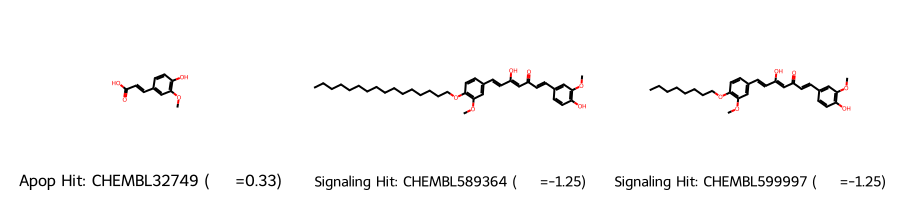

In [ ]:
from rdkit.Chem import Draw

mols_to_draw = []
legends = []

# Add the lone apoptosis hit
if not outlier_apop.empty:
    mols_to_draw.append(Chem.MolFromSmiles(outlier_apop.iloc[0]['smiles']))
    legends.append(f"Apop Hit: {outlier_apop.iloc[0]['chembl_id']} (Δ={outlier_apop.iloc[0]['delta_score']:.2f})")

# Add the top 2 signaling hits
for _, row in top_sign.head(2).iterrows():
    mols_to_draw.append(Chem.MolFromSmiles(row['smiles']))
    legends.append(f"Signaling Hit: {row['chembl_id']} (Δ={row['delta_score']:.2f})")

Draw.MolsToGridImage(mols_to_draw, molsPerRow=3, subImgSize=(300, 200), legends=legends)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract feature importances directly from both XGBoost models
imp_sign = xgb_sign.feature_importances_
imp_apop = xgb_apop.feature_importances_

# Get top 10 bits for each target
top_sign_idx = np.argsort(imp_sign)[::-1][:10]
top_apop_idx = np.argsort(imp_apop)[::-1][:10]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Signaling (EGFR) Top Bits
axes[0].barh([f"Bit {i}" for i in reversed(top_sign_idx)], imp_sign[top_sign_idx][::-1], color='#3498db')
axes[0].set_title("Top 10 Structural Bits Driving EGFR Potency", fontsize=11)
axes[0].set_xlabel("Relative Importance (Gain)")
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# Apoptosis (Caspase-3) Top Bits
axes[1].barh([f"Bit {i}" for i in reversed(top_apop_idx)], imp_apop[top_apop_idx][::-1], color='#e74c3c')
axes[1].set_title("Top 10 Structural Bits Driving Caspase-3 Potency", fontsize=11)
axes[1].set_xlabel("Relative Importance (Gain)")
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("feature_importances.png")
plt.show()

print(f"Top bit for EGFR: Bit {top_sign_idx[0]}")
print(f"Top bit for Caspase-3: Bit {top_apop_idx[0]}")